In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

pd.set_option("display.max_columns", None)

In [2]:
bls_path = "../../../data/processed/BLS/BLS_2025_processed.csv"
onet_path =  "../../../data/processed/ONET/O-Net_data_cleaned.csv"
owes_path =  "../../../data/processed/OEWS/OEWS_2025_cleaned.csv"

dfBLS = pd.read_csv(bls_path, dtype={"soc_code": "string"})
dfO_Net = pd.read_csv(onet_path, dtype={"soc_code": "string"})
dfOWES = pd.read_csv(owes_path, dtype={"occ_code": "string"})

print(f"dfBLS shape: {dfBLS.shape}")
print(f"dfO_Net shape: {dfO_Net.shape}")
print(f"dfOWES shape: {dfOWES.shape}")

dfBLS shape: (444, 58)
dfO_Net shape: (779850, 8)
dfOWES shape: (1394, 3)


In [3]:
print("BLS columns:", dfBLS.columns.tolist())
print("O-Net columns:", dfO_Net.columns.tolist())
print("OWES columns:", dfOWES.columns.tolist())

BLS columns: ['area', 'industry', 'occupation', 'employment', 'employment_percent_relative_standard_error', 'annual_mean_wage', 'wage_percent_relative_standard_error', 'annual_10th_percentile_wage', 'annual_25th_percentile_wage', 'annual_median_wage', 'annual_75th_percentile_wage', 'annual_90th_percentile_wage', 'log_employment', 'annual_mean_wage_winsorized', 'annual_10th_percentile_wage_winsorized', 'annual_25th_percentile_wage_winsorized', 'annual_median_wage_winsorized', 'annual_75th_percentile_wage_winsorized', 'annual_90th_percentile_wage_winsorized', 'wage_spread', 'wage_progression_ratio', 'year', 'log_employment_normalized', 'annual_mean_wage_winsorized_normalized', 'annual_10th_percentile_wage_winsorized_normalized', 'annual_25th_percentile_wage_winsorized_normalized', 'annual_median_wage_winsorized_normalized', 'annual_75th_percentile_wage_winsorized_normalized', 'annual_90th_percentile_wage_winsorized_normalized', 'wage_spread_normalized', 'wage_progression_ratio_normalized

In [4]:
dfBLS.head()

,area,industry,occupation,employment,employment_percent_relative_standard_error,annual_mean_wage,wage_percent_relative_standard_error,annual_10th_percentile_wage,annual_25th_percentile_wage,annual_median_wage,annual_75th_percentile_wage,annual_90th_percentile_wage,log_employment,annual_mean_wage_winsorized,annual_10th_percentile_wage_winsorized,annual_25th_percentile_wage_winsorized,annual_median_wage_winsorized,annual_75th_percentile_wage_winsorized,annual_90th_percentile_wage_winsorized,wage_spread,wage_progression_ratio,year,log_employment_normalized,annual_mean_wage_winsorized_normalized,annual_10th_percentile_wage_winsorized_normalized,annual_25th_percentile_wage_winsorized_normalized,annual_median_wage_winsorized_normalized,annual_75th_percentile_wage_winsorized_normalized,annual_90th_percentile_wage_winsorized_normalized,wage_spread_normalized,wage_progression_ratio_normalized,soc_code,industry_code,sector_11,sector_21,sector_22,sector_23,sector_31,sector_32,sector_33,sector_42,sector_44,sector_45,sector_48,sector_49,sector_51,sector_52,sector_53,sector_54,sector_55,sector_56,sector_61,sector_62,sector_71,sector_72,sector_81,sector_99,sector_cross_industry
0,National,"Cross-Industry, Private, Federal, State, and L...",All Occupations (00-0000),155495730.0,0.0,69770.0,0.1,31200.0,37590.0,50980.0,80520.0,128560.0,18.862129,69770.0,31200.0,37590.0,50980.0,80520.0,128560.0,97360.0,4.120513,2025,3.418252,-0.098478,-0.715940,-0.662300,-0.449972,-0.107018,0.197986,0.335858,0.954452,00-0000,000000,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
1,National,"Cross-industry, Private Ownership only (000001)",All Occupations (00-0000),132782040.0,0.0,68930.0,0.1,30670.0,37030.0,48990.0,79110.0,129020.0,18.704220,68930.0,30670.0,37030.0,48990.0,79110.0,129020.0,98350.0,4.206717,2025,3.330502,-0.134758,-0.785912,-0.711566,-0.549986,-0.152217,0.208182,0.359561,1.046911,00-0000,000001,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
2,National,"Sector 11 - Agriculture, Forestry, Fishing and...",All Occupations (00-0000),413350.0,0.0,44590.0,0.4,33880.0,34630.0,36740.0,46420.0,63350.0,12.932052,44590.0,33880.0,34630.0,36740.0,46420.0,63350.0,29470.0,1.869835,2025,0.122886,-1.186019,-0.362119,-0.922709,-1.165652,-1.200141,-1.247381,-1.289620,-1.459540,00-0000,11--12,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,National,Forestry and Logging (113000),All Occupations (00-0000),41620.0,0.1,56690.0,0.8,34670.0,44290.0,52640.0,63850.0,79040.0,10.636360,56690.0,34670.0,44290.0,52640.0,63850.0,79040.0,44370.0,2.279781,2025,-1.152839,-0.663412,-0.257821,-0.072860,-0.366543,-0.641398,-0.899615,-0.932872,-1.019848,00-0000,113000,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,National,Logging (113300),All Occupations (00-0000),41620.0,0.1,56690.0,0.8,34670.0,44290.0,52640.0,63850.0,79040.0,10.636360,56690.0,34670.0,44290.0,52640.0,63850.0,79040.0,44370.0,2.279781,2025,-1.152839,-0.663412,-0.257821,-0.072860,-0.366543,-0.641398,-0.899615,-0.932872,-1.019848,00-0000,113300,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [5]:
dfO_Net.head()

,O*NET-SOC_clean,Title,Tech Tool Used in Skill,Software or Tech Skills,Hot Technology,In Demand,Transferable or Soft Skills,Importance
0,111011,0,0.0,0,1,0,0,1.914776
1,111011,0,0.0,0,1,0,1,2.064546
2,111011,0,0.0,0,1,0,2,1.776527
3,111011,0,0.0,0,1,0,3,1.914776
4,111011,0,0.0,0,1,0,4,1.062238


In [6]:
dfOWES["soc_code"] = (
    dfOWES["occ_code"]
    .astype("string")
    .str.strip()
    .str.extract(r"(\d{2}-\d{4})")[0]
    .str.replace("-", "", regex=False)
)

In [7]:
dfOWES.head()

,occ_code,naics,year,soc_code
0,00-0000,0,2025,000000
1,11-0000,0,2025,110000
2,11-1000,0,2025,111000
3,11-1010,0,2025,111010
4,11-1011,0,2025,111011


In [8]:
print(dfOWES["soc_code"].head())
print("Unique SOC codes:", dfOWES["soc_code"].nunique())
print("Missing SOC codes:", dfOWES["soc_code"].isna().sum())

0    000000
1    110000
2    111000
3    111010
4    111011
Name: soc_code, dtype: string
Unique SOC codes: 1394
Missing SOC codes: 0


In [9]:
# 1. Clean dfOWES: ensure string, strip dash, take first 6 characters
dfOWES["soc_code_clean"] = (
    dfOWES["soc_code"]
    .astype("string")
    .str.replace("-", "", regex=False)
    .str.strip()
    .str[:6]
)

# 2. Clean dfO_Net: ensure string, strip dash, take first 6 characters
dfO_Net["onet_clean_6d"] = (
    dfO_Net["O*NET-SOC_clean"]
    .astype("string")
    .str.replace("-", "", regex=False)
    .str.strip()
    .str[:6]
)

# 3. Find matches again
matching_codes = (
    set(dfOWES["soc_code_clean"].dropna()) 
    & set(dfO_Net["onet_clean_6d"].dropna())
)

print("Matching SOC codes:", len(matching_codes))

Matching SOC codes: 759


In [10]:
dfO_Net.head()

,O*NET-SOC_clean,Title,Tech Tool Used in Skill,Software or Tech Skills,Hot Technology,In Demand,Transferable or Soft Skills,Importance,onet_clean_6d
0,111011,0,0.0,0,1,0,0,1.914776,111011
1,111011,0,0.0,0,1,0,1,2.064546,111011
2,111011,0,0.0,0,1,0,2,1.776527,111011
3,111011,0,0.0,0,1,0,3,1.914776,111011
4,111011,0,0.0,0,1,0,4,1.062238,111011


In [11]:
print("Unique NAICS codes:", dfOWES["naics"].nunique())
print(dfOWES["naics"].value_counts().head(15))

Unique NAICS codes: 1
naics
0    1394
Name: count, dtype: int64


In [12]:
# 1. Ensure both merge keys are clean, stripped strings
dfO_Net["O*NET-SOC_clean"] = dfO_Net["O*NET-SOC_clean"].astype(str).str.strip()
dfOWES["soc_code"] = dfOWES["soc_code"].astype(str).str.strip()

# 2. Perform the merge using the matching key names
dfONET_OWES = dfO_Net.merge(
    dfOWES[["soc_code", "naics", "year"]],
    left_on="O*NET-SOC_clean",
    right_on="soc_code",
    how="left",
        validate="many_to_many",
    indicator=True
)

print(dfONET_OWES["_merge"].value_counts())
print("Merged shape:", dfONET_OWES.shape)

_merge
both          762400
left_only      17450
right_only         0
Name: count, dtype: int64
Merged shape: (779850, 13)


In [13]:
print(
    "Matched O*NET rows:",
    (dfONET_OWES["_merge"] == "both").sum()
)

print(
    "Unmatched O*NET rows:",
    (dfONET_OWES["_merge"] == "left_only").sum()
)

Matched O*NET rows: 762400
Unmatched O*NET rows: 17450


In [14]:
unmatched = (
    dfONET_OWES.loc[
        dfONET_OWES["_merge"] == "left_only",
        ["soc_code"]
    ]
    .drop_duplicates()
    .sort_values("soc_code")
)

print("Unique unmatched SOC codes:", len(unmatched))
display(unmatched.head(20))

Unique unmatched SOC codes: 1


,soc_code
75300,NaN


In [15]:
naics_path =  "../../../data/raw/NAICS/NAICS_2025.csv"

dfNAICS = pd.read_csv(naics_path)

print("Shape:", dfNAICS.shape)
print("Columns:", dfNAICS.columns.tolist())

dfNAICS.head()

Shape: (83271, 32)
Columns: ['AREA', 'AREA_TITLE', 'AREA_TYPE', 'PRIM_STATE', 'NAICS', 'NAICS_TITLE', 'I_GROUP', 'OWN_CODE', 'OCC_CODE', 'OCC_TITLE', 'O_GROUP', 'TOT_EMP', 'EMP_PRSE', 'JOBS_1000', 'LOC_QUOTIENT', 'PCT_TOTAL', 'PCT_RPT', 'H_MEAN', 'A_MEAN', 'MEAN_PRSE', 'H_PCT10', 'H_PCT25', 'H_MEDIAN', 'H_PCT75', 'H_PCT90', 'A_PCT10', 'A_PCT25', 'A_MEDIAN', 'A_PCT75', 'A_PCT90', 'ANNUAL', 'HOURLY']


C:\Users\andre\AppData\Local\Temp\ipykernel_13408\2379439286.py:3: DtypeWarning: Columns (4: NAICS, 31: HOURLY) have mixed types. Specify dtype option on import or set low_memory=False.
  dfNAICS = pd.read_csv(naics_path)


,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,O_GROUP,TOT_EMP,EMP_PRSE,JOBS_1000,LOC_QUOTIENT,PCT_TOTAL,PCT_RPT,H_MEAN,A_MEAN,MEAN_PRSE,H_PCT10,H_PCT25,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,99,U.S.,1,US,113300,Logging,4-digit,5,00-0000,All Occupations,total,"41,620",0.1,NaN,NaN,100.00,100,27.26,"56,690",0.8,16.67,21.29,25.31,30.70,38.00,"34,670","44,290","52,640","63,850","79,040",NaN,NaN
1,99,U.S.,1,US,113300,Logging,4-digit,5,11-0000,Management Occupations,major,950,10.1,NaN,NaN,2.29,12,53.47,"111,220",3.4,26.80,37.10,48.25,65.94,84.80,"55,750","77,180","100,370","137,150","176,390",NaN,NaN
2,99,U.S.,1,US,113300,Logging,4-digit,5,11-1000,Top Executives,minor,550,10.7,NaN,NaN,1.31,7,47.17,"98,110",3.8,22.01,30.40,43.55,52.20,80.34,"45,770","63,220","90,590","108,580","167,110",NaN,NaN
3,99,U.S.,1,US,113300,Logging,4-digit,5,11-1020,General and Operations Managers,broad,540,10.8,NaN,NaN,1.30,7,47.13,"98,020",3.8,22.01,30.40,43.55,52.17,82.20,"45,770","63,220","90,590","108,510","170,980",NaN,NaN
4,99,U.S.,1,US,113300,Logging,4-digit,5,11-1021,General and Operations Managers,detailed,540,10.8,NaN,NaN,1.30,7,47.13,"98,020",3.8,22.01,30.40,43.55,52.17,82.20,"45,770","63,220","90,590","108,510","170,980",NaN,NaN


In [16]:
columns_to_keep = [
    "NAICS",
    "OCC_CODE",
    "OCC_TITLE",
    "O_GROUP",
    "TOT_EMP",
    "A_MEAN",
    "A_MEDIAN",
    "EMP_PRSE",
    "MEAN_PRSE"
]

dfOEWS_clean = dfNAICS[columns_to_keep].copy()

dfOEWS_clean.columns = dfOEWS_clean.columns.str.lower()

print("Shape:", dfOEWS_clean.shape)
dfOEWS_clean.head()

Shape: (83271, 9)


,naics,occ_code,occ_title,o_group,tot_emp,a_mean,a_median,emp_prse,mean_prse
0,113300,00-0000,All Occupations,total,"41,620","56,690","52,640",0.1,0.8
1,113300,11-0000,Management Occupations,major,950,"111,220","100,370",10.1,3.4
2,113300,11-1000,Top Executives,minor,550,"98,110","90,590",10.7,3.8
3,113300,11-1020,General and Operations Managers,broad,540,"98,020","90,590",10.8,3.8
4,113300,11-1021,General and Operations Managers,detailed,540,"98,020","90,590",10.8,3.8


In [17]:
dfOEWS_clean = dfOEWS_clean.rename(
    columns={
        "occ_code": "soc_code",
        "naics": "industry_code"
    }
)

dfOEWS_clean["soc_code"] = (
    dfOEWS_clean["soc_code"]
    .astype("string")
    .str.strip()
)

dfOEWS_clean["industry_code"] = (
    dfOEWS_clean["industry_code"]
    .astype("string")
    .str.strip()
)

dfBLS["industry_code"] = (
    dfBLS["industry_code"]
    .astype("string")
    .str.strip()
)

In [18]:
matching_industries = (
    set(dfOEWS_clean["industry_code"].dropna())
    & set(dfBLS["industry_code"].dropna())
)

print("Matching industry codes:", len(matching_industries))
print("Examples:", sorted(matching_industries)[:15])

Matching industry codes: 247
Examples: ['113300', '115100', '115200', '211100', '212100', '212200', '212300', '213100', '221100', '221200', '221300', '236100', '236200', '237100', '237200']


In [19]:
# 1. Clean and truncate dfOEWS_clean to 6 digits
dfOEWS_clean["soc_6d"] = (
    dfOEWS_clean["soc_code"]
    .astype(str)
    .str.replace("-", "", regex=False)
    .str.split(".")  # Removes trailing decimals like .0
    .str[0]
    .str.strip()
    .str[:6]
)

# 2. Clean and truncate dfO_Net to 6 digits
dfO_Net["onet_6d"] = (
    dfO_Net["O*NET-SOC_clean"]
    .astype(str)
    .str.replace("-", "", regex=False)
    .str.split(".")  # Removes trailing decimals like .0
    .str[0]
    .str.strip()
    .str[:6]
)

# 3. Calculate intersection again
matching_occupations = (
    set(dfOEWS_clean["soc_6d"].dropna())
    & set(dfO_Net["onet_6d"].dropna())
)

print("Matching SOC codes:", len(matching_occupations))


Matching SOC codes: 759


In [20]:
print(dfOEWS_clean["o_group"].value_counts())

o_group
detailed    37799
broad       29215
minor       11942
major        4068
total         247
Name: count, dtype: int64


In [21]:
dfOEWS_detailed = dfOEWS_clean[
    dfOEWS_clean["o_group"] == "detailed"
].copy()

print("Shape:", dfOEWS_detailed.shape)

Shape: (37799, 10)


In [22]:
dfBLS_OEWS = dfOEWS_detailed.merge(
    dfBLS,
    on="industry_code",
    how="left",
    validate="many_to_one",
    indicator=True
)

print(dfBLS_OEWS["_merge"].value_counts())
print("Shape:", dfBLS_OEWS.shape)

_merge
both          37799
left_only         0
right_only        0
Name: count, dtype: int64
Shape: (37799, 68)


In [23]:
print([col for col in dfBLS_OEWS.columns if "soc_code" in col])

['soc_code_x', 'soc_code_y']


In [24]:
dfBLS_OEWS = dfBLS_OEWS.rename(
    columns={"soc_code_x": "soc_code"}
)

dfBLS_OEWS = dfBLS_OEWS.drop(
    columns=["soc_code_y"]
)

In [25]:
print("Matched rows:", (dfBLS_OEWS["_merge"] == "both").sum())
print("Unmatched rows:", (dfBLS_OEWS["_merge"] == "left_only").sum())

print("Unique SOC codes:", dfBLS_OEWS["soc_code"].nunique())
print("Unique industry codes:", dfBLS_OEWS["industry_code"].nunique())

Matched rows: 37799
Unmatched rows: 0
Unique SOC codes: 830
Unique industry codes: 247


In [26]:
onet_features = [
    "Title",
    "Tech Tool Used in Skill",
    "Software or Tech Skills",
    "Hot Technology",
    "In Demand",
    "Transferable or Soft Skills",
    "Importance"
]

for col in onet_features:
    print(f"\n{col}")
    print(dfO_Net[col].value_counts().head(10))


Title
Title
114    10750
115    10725
127     8350
110     8050
101     7775
113     7325
109     7200
107     6950
126     6675
112     6525
Name: count, dtype: int64

Tech Tool Used in Skill
Tech Tool Used in Skill
3.295837    21225
3.367296    20175
3.555348    19400
3.401197    15875
3.433987    15550
3.871201    10675
3.135494     9150
3.806662     7025
2.079442     6825
4.787492     5900
Name: count, dtype: int64

Software or Tech Skills
Software or Tech Skills
12    71225
1     62025
35    38700
14    29050
47    28425
6     28125
19    27025
29    25150
17    22850
52    22575
Name: count, dtype: int64

Hot Technology
Hot Technology
0    494550
1    285300
Name: count, dtype: int64

In Demand
In Demand
0    719925
1     59925
Name: count, dtype: int64

Transferable or Soft Skills
Transferable or Soft Skills
0    31194
1    31194
2    31194
3    31194
4    31194
5    31194
6    31194
7    31194
8    31194
9    31194
Name: count, dtype: int64

Importance
Importance
-1.679707    

In [27]:
dfONET_aggregated = (
    dfO_Net.groupby("O*NET-SOC_clean", as_index=False)
    .agg(
        unique_titles=("Title", "nunique"),
        unique_software_skills=("Software or Tech Skills", "nunique"),
        unique_soft_skills=("Transferable or Soft Skills", "nunique"),
        hot_technology_rate=("Hot Technology", "mean"),
        in_demand_rate=("In Demand", "mean"),
        average_importance=("Importance", "mean"),
        skill_record_count=("O*NET-SOC_clean", "size")
    )
)

print("Aggregated shape:", dfONET_aggregated.shape)
dfONET_aggregated.head()

Aggregated shape: (785, 8)


,O*NET-SOC_clean,unique_titles,unique_software_skills,unique_soft_skills,hot_technology_rate,in_demand_rate,average_importance,skill_record_count
0,111011,2,27,25,0.434783,0.115942,0.498461,1725
1,111021,1,53,25,0.347518,0.021277,0.197258,3525
2,112011,1,27,25,0.375000,0.041667,0.078364,1800
3,112021,1,46,25,0.441558,0.038961,0.176981,3850
4,112022,1,40,25,0.378641,0.048544,0.261314,2575


In [28]:
# 1. Force both key columns to be strings to prevent type errors
dfBLS_OEWS["soc_6d"] = dfBLS_OEWS["soc_6d"].astype(str).str.strip()
dfBLS_OEWS["soc_6d"] = dfBLS_OEWS["soc_code"].str.replace("-", "", regex=False)
dfONET_aggregated["O*NET-SOC_clean"] = dfONET_aggregated["O*NET-SOC_clean"].astype(str).str.strip()

# 2. Run the merge using left_on and right_on
dfFinal = dfBLS_OEWS.merge(
    dfONET_aggregated,
    left_on="soc_6d",                # dash-free SOC (111011), same format as O*NET
    right_on="O*NET-SOC_clean",      # Key column in dfONET_aggregated
    how="left",
    validate="many_to_one",          # Works perfectly now that ONET is aggregated!
    indicator="onet_merge"
)

print(dfFinal["onet_merge"].value_counts())
print("Final shape:", dfFinal.shape)

onet_merge
both          34715
left_only      3084
right_only        0
Name: count, dtype: int64
Final shape: (37799, 76)


In [29]:
print("Original BLS + OEWS rows:", len(dfBLS_OEWS))
print("Final merged rows:", len(dfFinal))

print("Unique SOC codes:", dfFinal["soc_code"].nunique())
print("Unique industries:", dfFinal["industry_code"].nunique())

print("Missing O*NET matches:",
      (dfFinal["onet_merge"] == "left_only").sum())

Original BLS + OEWS rows: 37799
Final merged rows: 37799
Unique SOC codes: 830
Unique industries: 247
Missing O*NET matches: 3084


In [30]:
unmatched_soc = (
    dfFinal.loc[
        dfFinal["onet_merge"] == "left_only",
        ["soc_code", "occ_title"]
    ]
    .drop_duplicates()
    .sort_values("soc_code")
)

print("Unique unmatched occupations:", len(unmatched_soc))
display(unmatched_soc.head(20))

Unique unmatched occupations: 71


,soc_code,occ_title
19814,11-9039,"Education Administrators, All Other"
3,13-1020,Buyers and Purchasing Agents
882,13-2020,Property Appraisers and Assessors
238,13-2051,Financial and Investment Analysts
886,13-2054,Financial Risk Specialists
710,17-3019,"Drafters, All Other"
270,17-3028,Calibration Technologists and Technicians
6431,19-1099,"Life Scientists, All Other"
280,19-4044,Hydrologic Technicians
20489,21-1018,"Substance Abuse, Behavioral Disorder, and Ment..."


In [31]:
print(
    dfFinal.isna()
    .sum()
    .loc[lambda x: x > 0]
    .sort_values(ascending=False)
)

O*NET-SOC_clean           3084
unique_titles             3084
unique_software_skills    3084
unique_soft_skills        3084
hot_technology_rate       3084
in_demand_rate            3084
average_importance        3084
skill_record_count        3084
dtype: int64


In [32]:
print(
    "Duplicate SOC-industry combinations:",
    dfFinal.duplicated(
        subset=["soc_code", "industry_code"]
    ).sum()
)

Duplicate SOC-industry combinations: 0


In [33]:
dfONET_aggregated.head()

,O*NET-SOC_clean,unique_titles,unique_software_skills,unique_soft_skills,hot_technology_rate,in_demand_rate,average_importance,skill_record_count
0,111011,2,27,25,0.434783,0.115942,0.498461,1725
1,111021,1,53,25,0.347518,0.021277,0.197258,3525
2,112011,1,27,25,0.375000,0.041667,0.078364,1800
3,112021,1,46,25,0.441558,0.038961,0.176981,3850
4,112022,1,40,25,0.378641,0.048544,0.261314,2575


In [34]:
onet_columns = [
    "unique_titles",
    "unique_software_skills",
    "unique_soft_skills",
    "hot_technology_rate",
    "in_demand_rate",
    "average_importance",
    "skill_record_count"
]

print(dfFinal[onet_columns].nunique(dropna=True))

unique_titles               9
unique_software_skills     58
unique_soft_skills          1
hot_technology_rate       291
in_demand_rate            214
average_importance        701
skill_record_count        145
dtype: int64


In [35]:
from pathlib import Path

output_path = Path("../../../data/merges/BLS_OEWS_ONET_merged.csv")

output_path.parent.mkdir(parents=True, exist_ok=True)

dfFinal.to_csv(output_path, index=False)

print("Saved to:", output_path.resolve())
print("Final shape:", dfFinal.shape)

Saved to: C:\Users\andre\Desktop\BTT Project\Sage-Road-Solutions-1A-workforce-pell-opportunity-score\data\merges\BLS_OEWS_ONET_merged.csv
Final shape: (37799, 76)


In [36]:
dfFinal = dfFinal.drop(columns=["unique_soft_skills"])

print("Final shape:", dfFinal.shape)

Final shape: (37799, 75)


In [37]:
dfFinal.to_csv(output_path, index=False)

print("Updated dataset:", output_path.resolve())
print("Final shape:", dfFinal.shape)

Updated dataset: C:\Users\andre\Desktop\BTT Project\Sage-Road-Solutions-1A-workforce-pell-opportunity-score\data\merges\BLS_OEWS_ONET_merged.csv
Final shape: (37799, 75)


In [38]:
onet_features = [
    "unique_titles",
    "unique_software_skills",
    "hot_technology_rate",
    "in_demand_rate",
    "average_importance",
    "skill_record_count"
]

dfFinal[onet_features].describe().T

,count,mean,std,min,25%,50%,75%,max
unique_titles,34715.0,1.372577,1.139403,1.000000,1.000000,1.000000,1.000000,9.000000
unique_software_skills,34715.0,21.953997,16.531438,1.000000,10.000000,16.000000,29.000000,82.000000
hot_technology_rate,34715.0,0.409086,0.185059,0.000000,0.291667,0.378641,0.500000,1.000000
in_demand_rate,34715.0,0.073643,0.081880,0.000000,0.000000,0.054545,0.118644,0.592593
average_importance,34715.0,-0.082918,0.348719,-1.103668,-0.343297,-0.044217,0.180668,0.740117
skill_record_count,34715.0,2013.739018,3097.399464,25.000000,325.000000,875.000000,2575.000000,30550.000000


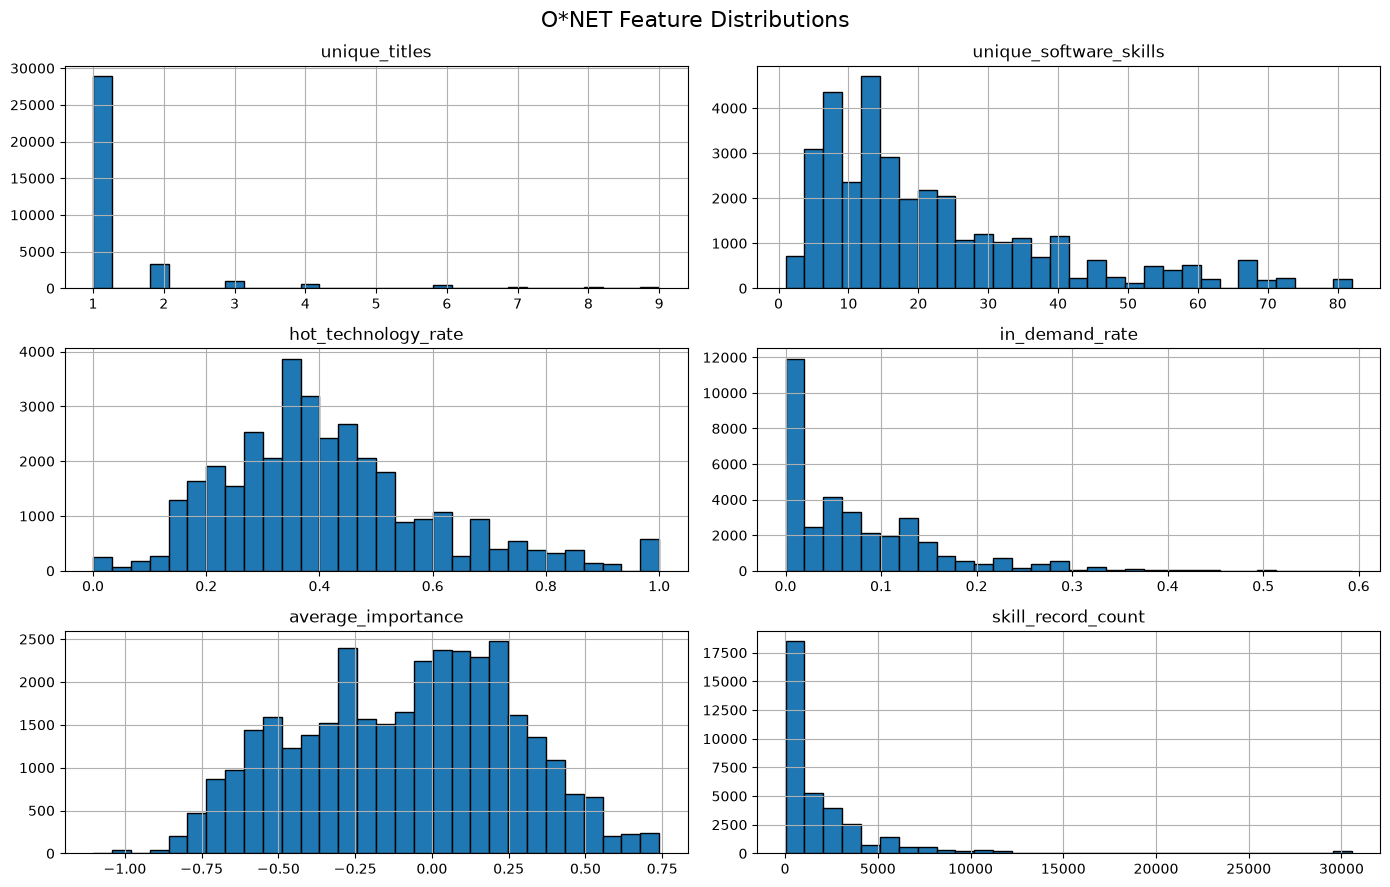

In [39]:
import matplotlib.pyplot as plt

dfFinal[onet_features].hist(
    bins=30,
    figsize=(14, 9),
    edgecolor="black"
)

plt.suptitle("O*NET Feature Distributions", fontsize=16)
plt.tight_layout()
plt.show()

In [40]:
# Cells below use snake_case O*NET names and dashed SOC codes (11-1011) to match OEWS soc_code
dfO_Net = dfO_Net.rename(columns={
    "Title": "title",
    "Tech Tool Used in Skill": "tech_tool_used_in_skill",
    "Software or Tech Skills": "software_or_tech_skills",
    "Hot Technology": "hot_technology",
    "In Demand": "in_demand",
    "Transferable or Soft Skills": "transferable_or_soft_skills",
    "Importance": "importance"
})

def to_dashed_soc(code):
    code = code.astype(str).str.strip().str.zfill(6)
    return code.str[:2] + "-" + code.str[2:6]

dfO_Net["soc_code"] = to_dashed_soc(dfO_Net["O*NET-SOC_clean"])
dfONET_aggregated["soc_code"] = to_dashed_soc(dfONET_aggregated["O*NET-SOC_clean"])

print("O*NET columns:", dfO_Net.columns.tolist())


O*NET columns: ['O*NET-SOC_clean', 'title', 'tech_tool_used_in_skill', 'software_or_tech_skills', 'hot_technology', 'in_demand', 'transferable_or_soft_skills', 'importance', 'onet_clean_6d', 'onet_6d', 'soc_code']


In [41]:
print("Title data type:", dfO_Net["title"].dtype)
print("Unique title values:", dfO_Net["title"].nunique())

print("\nExample title values:")
print(dfO_Net["title"].drop_duplicates().head(20).tolist())

print("\nTitles per occupation:")
print(
    dfO_Net.groupby("soc_code")["title"]
    .nunique()
    .describe()
)

Title data type: int64
Unique title values: 910

Example title values:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]

Titles per occupation:
count    785.000000
mean       1.159236
std        0.686138
min        1.000000
25%        1.000000
50%        1.000000
75%        1.000000
max        9.000000
Name: title, dtype: float64


In [42]:
print("Importance statistics:")
print(dfO_Net["importance"].describe())

print("\nMissing importance values:")
print(dfO_Net["importance"].isna().sum())

print("\nSample importance values:")
print(dfO_Net["importance"].drop_duplicates().head(20).tolist())

Importance statistics:
count    7.798500e+05
mean    -1.959288e-16
std      1.000001e+00
min     -1.679707e+00
25%     -8.156489e-01
50%      1.866589e-01
75%      7.626979e-01
max      2.928604e+00
Name: importance, dtype: float64

Missing importance values:
0

Sample importance values:
[1.914775867225282, 2.0645460012718635, 1.7765265127207452, 1.0622381811139716, 0.7626979130208088, 2.214316135318445, -0.8156488842393197, -1.5414579953881378, -1.679707349892675, -0.5276293956882013, -0.6658787501927383, -1.103668372790438, 2.6405849783741004, 1.6382771582162083, 1.488507024169627, 0.9124680470673904, 0.486199204011735, -0.239609907137083, 1.3387368901230454, 1.2004875356185083]


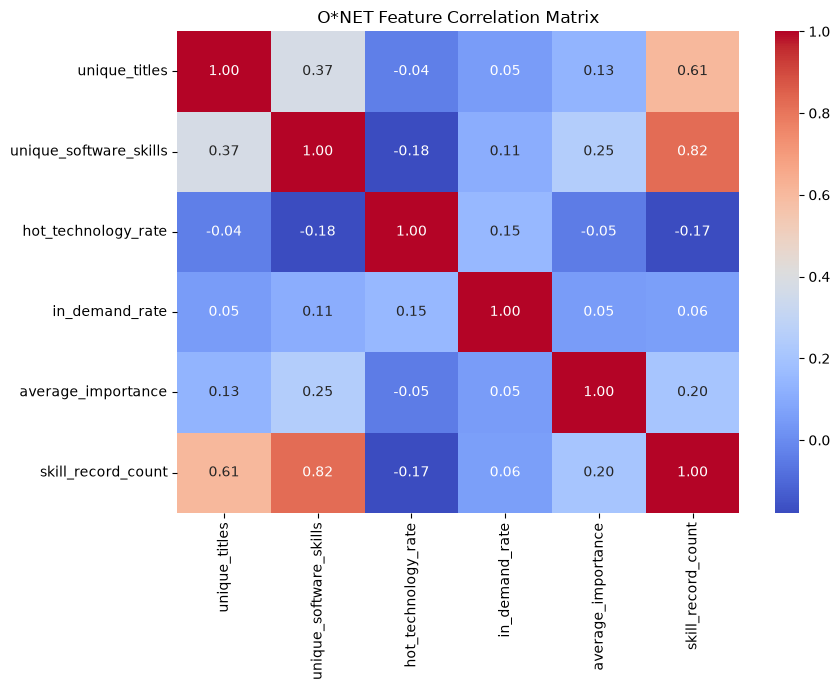

In [43]:
import seaborn as sns

plt.figure(figsize=(9, 7))

sns.heatmap(
    dfONET_aggregated[onet_features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("O*NET Feature Correlation Matrix")
plt.tight_layout()
plt.show()

In [44]:
print("Total O*NET rows:", len(dfO_Net))

print("Exact duplicate rows:",
      dfO_Net.duplicated().sum())

print("Unique rows:",
      len(dfO_Net.drop_duplicates()))

print("\nRecords per occupation:")
print(
    dfO_Net.groupby("soc_code")
    .size()
    .describe()
)

Total O*NET rows: 779850
Exact duplicate rows: 0
Unique rows: 779850

Records per occupation:
count      785.000000
mean       993.439490
std       1781.145481
min         25.000000
25%        250.000000
50%        500.000000
75%        975.000000
max      30550.000000
dtype: float64


In [45]:
dfONET_unique = dfO_Net.drop_duplicates().copy()

dfONET_comparison = (
    dfONET_unique.groupby("soc_code")
    .agg(
        dedup_hot_rate=("hot_technology", "mean"),
        dedup_demand_rate=("in_demand", "mean"),
        dedup_importance=("importance", "mean"),
        dedup_record_count=("soc_code", "size")
    )
    .reset_index()
)

dfONET_comparison = dfONET_aggregated.merge(
    dfONET_comparison,
    on="soc_code",
    how="left"
)

dfONET_comparison[
    [
        "hot_technology_rate", "dedup_hot_rate",
        "in_demand_rate", "dedup_demand_rate",
        "average_importance", "dedup_importance",
        "skill_record_count", "dedup_record_count"
    ]
].describe().T

,count,mean,std,min,25%,50%,75%,max
hot_technology_rate,785.0,0.431872,0.211663,0.000000,0.291667,0.400000,0.571429,1.000000
dedup_hot_rate,785.0,0.431872,0.211663,0.000000,0.291667,0.400000,0.571429,1.000000
in_demand_rate,785.0,0.066484,0.096467,0.000000,0.000000,0.022222,0.103448,0.592593
dedup_demand_rate,785.0,0.066484,0.096467,0.000000,0.000000,0.022222,0.103448,0.592593
average_importance,785.0,-0.114844,0.313172,-1.103668,-0.325785,-0.097975,0.104631,0.740117
dedup_importance,785.0,-0.114844,0.313172,-1.103668,-0.325785,-0.097975,0.104631,0.740117
skill_record_count,785.0,993.439490,1781.145481,25.000000,250.000000,500.000000,975.000000,30550.000000
dedup_record_count,785.0,993.439490,1781.145481,25.000000,250.000000,500.000000,975.000000,30550.000000


In [46]:
onet_features_to_keep = [
    "unique_software_skills",
    "hot_technology_rate",
    "in_demand_rate",
    "average_importance"
]

In [47]:
print("Unique soft-skill categories per occupation:")
print(
    dfO_Net.groupby("soc_code")["transferable_or_soft_skills"]
    .nunique()
    .value_counts()
)

print("\nRecords per occupation divided by 25:")
print(
    (dfO_Net.groupby("soc_code").size() / 25)
    .describe()
)

print("\nRepeated records excluding soft skills:")
print(
    dfO_Net.drop(
        columns=["transferable_or_soft_skills"]
    ).duplicated().sum()
)

Unique soft-skill categories per occupation:
transferable_or_soft_skills
25    785
Name: count, dtype: int64

Records per occupation divided by 25:
count     785.000000
mean       39.737580
std        71.245819
min         1.000000
25%        10.000000
50%        20.000000
75%        39.000000
max      1222.000000
dtype: float64

Repeated records excluding soft skills:
354141


In [48]:
print(
    dfO_Net.groupby("transferable_or_soft_skills")[
        "importance"
    ].agg(["count", "mean", "std"]).head(25)
)

                             count      mean       std
transferable_or_soft_skills                           
0                            31194  0.868392  0.490551
1                            31194  0.851348  0.432200
2                            31194  0.501377  0.520543
3                            31194  0.332600  0.566568
4                            31194  0.582251  0.574743
5                            31194  0.617064  0.515054
6                            31194  1.150232  0.504458
7                            31194 -0.121006  0.794917
8                            31194 -0.589866  0.606118
9                            31194 -1.026913  0.703222
10                           31194 -1.409189  0.546651
11                           31194 -0.461832  0.916356
12                           31194 -0.098747  0.748102
13                           31194 -0.696148  0.850436
14                           31194 -1.168946  0.779464
15                           31194 -0.645126  0.867640
16        

In [49]:
tech_columns = [
    "soc_code",
    "title",
    "tech_tool_used_in_skill",
    "software_or_tech_skills",
    "hot_technology",
    "in_demand"
]

tech_group_sizes = (
    dfO_Net.groupby(tech_columns, dropna=False)
    .agg(
        rows=("importance", "size"),
        soft_skill_categories=("transferable_or_soft_skills", "nunique")
    )
    .reset_index()
)

print("Number of technology groups:", len(tech_group_sizes))

print("\nSoft-skill categories per technology group:")
print(tech_group_sizes["soft_skill_categories"].value_counts().head(15))

print("\nRows per technology group:")
print(tech_group_sizes["rows"].describe())

Number of technology groups: 31194

Soft-skill categories per technology group:
soft_skill_categories
25    31194
Name: count, dtype: int64

Rows per technology group:
count    31194.0
mean        25.0
std          0.0
min         25.0
25%         25.0
50%         25.0
75%         25.0
max         25.0
Name: rows, dtype: float64


In [50]:
importance_variation = (
    dfO_Net.groupby(
        ["soc_code", "transferable_or_soft_skills"]
    )["importance"]
    .nunique()
)

print("Unique importance values per occupation-soft skill pair:")
print(importance_variation.value_counts().head(15))

Unique importance values per occupation-soft skill pair:
importance
1    18194
2      974
3      258
4      118
5       43
6       23
7        9
8        5
9        1
Name: count, dtype: int64


In [51]:
dfONET_tech = dfO_Net[
    [
        "soc_code",
        "title",
        "tech_tool_used_in_skill",
        "software_or_tech_skills",
        "hot_technology",
        "in_demand"
    ]
].drop_duplicates()

print("Original O*NET rows:", len(dfO_Net))
print("Unique technology groups:", len(dfONET_tech))

Original O*NET rows: 779850
Unique technology groups: 31194


In [52]:
dfONET_tech_agg = (
    dfONET_tech.groupby("soc_code", as_index=False)
    .agg(
        unique_software_skills=("software_or_tech_skills", "nunique"),
        hot_technology_rate=("hot_technology", "mean"),
        in_demand_rate=("in_demand", "mean"),
        technology_record_count=("soc_code", "size")
    )
)

print("Shape:", dfONET_tech_agg.shape)
display(dfONET_tech_agg.head())

Shape: (785, 5)


,soc_code,unique_software_skills,hot_technology_rate,in_demand_rate,technology_record_count
0,11-1011,27,0.434783,0.115942,69
1,11-1021,53,0.347518,0.021277,141
2,11-2011,27,0.375000,0.041667,72
3,11-2021,46,0.441558,0.038961,154
4,11-2022,40,0.378641,0.048544,103


In [53]:
importance_check = (
    dfO_Net.groupby(
        ["soc_code", "transferable_or_soft_skills"]
    )["importance"]
    .agg(["nunique", "min", "max"])
    .reset_index()
)

importance_check["range"] = (
    importance_check["max"] - importance_check["min"]
)

print("Pairs with multiple importance values:",
      (importance_check["nunique"] > 1).sum())

print("\nImportance range statistics:")
print(importance_check["range"].describe())

display(
    importance_check.sort_values(
        "range", ascending=False
    ).head(10)
)

Pairs with multiple importance values: 1431

Importance range statistics:
count    19625.000000
mean         0.043324
std          0.198449
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          2.741946
Name: range, dtype: float64


,soc_code,transferable_or_soft_skills,nunique,min,max,range
2789,17-2199,14,7,-1.679707,1.062238,2.741946
2082,15-1299,7,9,-1.103668,1.488507,2.592175
1067,13-1041,17,6,-1.541458,0.912468,2.453926
6638,27-2012,13,4,-1.679707,0.624449,2.304156
13835,47-2152,10,2,0.336429,2.640585,2.304156
8717,29-2099,17,3,-1.679707,0.624449,2.304156
2582,17-2111,7,2,-0.815649,1.488507,2.304156
2784,17-2199,9,8,-1.541458,0.762698,2.304156
1062,13-1041,12,7,-1.241918,1.062238,2.304156
8715,29-2099,15,3,-1.679707,0.486199,2.165907


In [54]:
dfONET_importance = (
    dfO_Net.groupby(
        ["soc_code", "transferable_or_soft_skills"],
        as_index=False
    )
    .agg(
        soft_skill_importance=("importance", "mean")
    )
)

print("Shape:", dfONET_importance.shape)
display(dfONET_importance.head())

Shape: (19625, 3)


,soc_code,transferable_or_soft_skills,soft_skill_importance
0,11-1011,0,1.830624
1,11-1011,1,1.889230
2,11-1011,2,1.734451
3,11-1011,3,1.564143
4,11-1011,4,1.016656


In [55]:
dfONET_importance_agg = (
    dfONET_importance.groupby("soc_code", as_index=False)
    .agg(
        average_importance=("soft_skill_importance", "mean"),
        importance_std=("soft_skill_importance", "std")
    )
)

print("Shape:", dfONET_importance_agg.shape)
display(dfONET_importance_agg.head())

Shape: (785, 3)


,soc_code,average_importance,importance_std
0,11-1011,0.498461,1.429460
1,11-1021,0.197258,1.172754
2,11-2011,0.078364,1.242363
3,11-2021,0.176981,1.310834
4,11-2022,0.261314,1.372574


In [56]:
dfONET_final = dfONET_tech_agg.merge(
    dfONET_importance_agg,
    on="soc_code",
    how="left",
    validate="one_to_one"
)

print("Final O*NET shape:", dfONET_final.shape)
display(dfONET_final.head())

Final O*NET shape: (785, 7)


,soc_code,unique_software_skills,hot_technology_rate,in_demand_rate,technology_record_count,average_importance,importance_std
0,11-1011,27,0.434783,0.115942,69,0.498461,1.429460
1,11-1021,53,0.347518,0.021277,141,0.197258,1.172754
2,11-2011,27,0.375000,0.041667,72,0.078364,1.242363
3,11-2021,46,0.441558,0.038961,154,0.176981,1.310834
4,11-2022,40,0.378641,0.048544,103,0.261314,1.372574


In [57]:
importance_comparison = dfONET_aggregated[
    ["soc_code", "average_importance"]
].merge(
    dfONET_importance_agg,
    on="soc_code",
    suffixes=("_old", "_new")
)

importance_comparison["difference"] = (
    importance_comparison["average_importance_new"]
    - importance_comparison["average_importance_old"]
)

print(importance_comparison["difference"].describe())

print("\nLargest differences:")
display(
    importance_comparison.reindex(
        importance_comparison["difference"].abs()
        .sort_values(ascending=False).index
    ).head(10)
)

count    7.850000e+02
mean     9.815828e-19
std      3.483776e-17
min     -2.220446e-16
25%      0.000000e+00
50%      0.000000e+00
75%      1.734723e-18
max      1.110223e-16
Name: difference, dtype: float64

Largest differences:


,soc_code,average_importance_old,average_importance_new,importance_std,difference
520,45-2041,-1.035005,-1.035005,0.553592,-2.220446e-16
779,53-7065,-0.620256,-0.620256,0.643485,-1.110223e-16
422,39-3011,-0.753898,-0.753898,0.841371,1.110223e-16
776,53-7062,-0.536308,-0.536308,0.601088,1.110223e-16
714,51-9031,-0.672330,-0.672330,0.708731,1.110223e-16
783,53-7081,-0.561270,-0.561270,0.781426,-1.110223e-16
680,51-6011,-0.572330,-0.572330,0.636372,-1.110223e-16
77,15-1244,0.740117,0.740117,0.679323,-1.110223e-16
435,39-5092,-0.677400,-0.677400,0.752034,-1.110223e-16
436,39-5093,-0.792146,-0.792146,0.727350,-1.110223e-16


In [58]:
dfFinal_corrected = dfBLS_OEWS.drop(
    columns=["_merge"], errors="ignore"
).merge(
    dfONET_final,
    on="soc_code",
    how="left",
    validate="many_to_one",
    indicator="onet_merge"
)

print("Final shape:", dfFinal_corrected.shape)
print(dfFinal_corrected["onet_merge"].value_counts())

Final shape: (37799, 73)
onet_merge
both          34715
left_only      3084
right_only        0
Name: count, dtype: int64


In [59]:
print("Total rows:", len(dfFinal_corrected))

print(
    "Duplicate SOC-industry combinations:",
    dfFinal_corrected.duplicated(
        subset=["soc_code", "industry_code"]
    ).sum()
)

print(
    "\nMissing O*NET features:",
    dfFinal_corrected[
        dfONET_final.columns.drop("soc_code")
    ].isna().sum()
)

Total rows: 37799
Duplicate SOC-industry combinations: 0

Missing O*NET features: unique_software_skills     3084
hot_technology_rate        3084
in_demand_rate             3084
technology_record_count    3084
average_importance         3084
importance_std             3084
dtype: int64


In [60]:
dfFinal_corrected.to_csv(output_path, index=False)

print("Saved corrected dataset:", output_path.resolve())
print("Final shape:", dfFinal_corrected.shape)

Saved corrected dataset: C:\Users\andre\Desktop\BTT Project\Sage-Road-Solutions-1A-workforce-pell-opportunity-score\data\merges\BLS_OEWS_ONET_merged.csv
Final shape: (37799, 73)


In [61]:
dfSaved = pd.read_csv(
    output_path,
    dtype={"soc_code": "string", "industry_code": "string"}
)

print("Saved dataset shape:", dfSaved.shape)
print("Duplicate records:", dfSaved.duplicated(
    subset=["soc_code", "industry_code"]
).sum())

display(dfSaved.head())

Saved dataset shape: (37799, 73)
Duplicate records: 0


,industry_code,soc_code,occ_title,o_group,tot_emp,a_mean,a_median,emp_prse,mean_prse,soc_6d,area,industry,occupation,employment,employment_percent_relative_standard_error,annual_mean_wage,wage_percent_relative_standard_error,annual_10th_percentile_wage,annual_25th_percentile_wage,annual_median_wage,annual_75th_percentile_wage,annual_90th_percentile_wage,log_employment,annual_mean_wage_winsorized,annual_10th_percentile_wage_winsorized,annual_25th_percentile_wage_winsorized,annual_median_wage_winsorized,annual_75th_percentile_wage_winsorized,annual_90th_percentile_wage_winsorized,wage_spread,wage_progression_ratio,year,log_employment_normalized,annual_mean_wage_winsorized_normalized,annual_10th_percentile_wage_winsorized_normalized,annual_25th_percentile_wage_winsorized_normalized,annual_median_wage_winsorized_normalized,annual_75th_percentile_wage_winsorized_normalized,annual_90th_percentile_wage_winsorized_normalized,wage_spread_normalized,wage_progression_ratio_normalized,sector_11,sector_21,sector_22,sector_23,sector_31,sector_32,sector_33,sector_42,sector_44,sector_45,sector_48,sector_49,sector_51,sector_52,sector_53,sector_54,sector_55,sector_56,sector_61,sector_62,sector_71,sector_72,sector_81,sector_99,sector_cross_industry,unique_software_skills,hot_technology_rate,in_demand_rate,technology_record_count,average_importance,importance_std,onet_merge
0,113300,11-1021,General and Operations Managers,detailed,540,"98,020","90,590",10.8,3.8,111021,National,Logging (113300),All Occupations (00-0000),41620.0,0.1,56690.0,0.8,34670.0,44290.0,52640.0,63850.0,79040.0,10.63636,56690.0,34670.0,44290.0,52640.0,63850.0,79040.0,44370.0,2.279781,2025,-1.152839,-0.663412,-0.257821,-0.07286,-0.366543,-0.641398,-0.899615,-0.932872,-1.019848,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,53.0,0.347518,0.021277,141.0,0.197258,1.172754,both
1,113300,11-3051,Industrial Production Managers,detailed,**,"115,890","116,680",**,3.6,113051,National,Logging (113300),All Occupations (00-0000),41620.0,0.1,56690.0,0.8,34670.0,44290.0,52640.0,63850.0,79040.0,10.63636,56690.0,34670.0,44290.0,52640.0,63850.0,79040.0,44370.0,2.279781,2025,-1.152839,-0.663412,-0.257821,-0.07286,-0.366543,-0.641398,-0.899615,-0.932872,-1.019848,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,36.0,0.375796,0.057325,157.0,0.536207,0.862333,both
2,113300,11-9199,"Managers, All Other",detailed,210,"122,760","129,280",18.5,10.2,119199,National,Logging (113300),All Occupations (00-0000),41620.0,0.1,56690.0,0.8,34670.0,44290.0,52640.0,63850.0,79040.0,10.63636,56690.0,34670.0,44290.0,52640.0,63850.0,79040.0,44370.0,2.279781,2025,-1.152839,-0.663412,-0.257821,-0.07286,-0.366543,-0.641398,-0.899615,-0.932872,-1.019848,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,41.0,0.327586,0.077586,232.0,0.058067,1.068798,both
3,113300,13-1020,Buyers and Purchasing Agents,detailed,120,"67,530","76,270",26.9,5.0,131020,National,Logging (113300),All Occupations (00-0000),41620.0,0.1,56690.0,0.8,34670.0,44290.0,52640.0,63850.0,79040.0,10.63636,56690.0,34670.0,44290.0,52640.0,63850.0,79040.0,44370.0,2.279781,2025,-1.152839,-0.663412,-0.257821,-0.07286,-0.366543,-0.641398,-0.899615,-0.932872,-1.019848,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,left_only
4,113300,13-1082,Project Management Specialists,detailed,40,"98,340","114,990",30.8,8.6,131082,National,Logging (113300),All Occupations (00-0000),41620.0,0.1,56690.0,0.8,34670.0,44290.0,52640.0,63850.0,79040.0,10.63636,56690.0,34670.0,44290.0,52640.0,63850.0,79040.0,44370.0,2.279781,2025,-1.152839,-0.663412,-0.257821,-0.07286,-0.366543,-0.641398,-0.899615,-0.932872,-1.019848,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,35.0,0.477778,0.066667,90.0,0.041497,1.102093,both


In [62]:
oews_numeric_columns = [
    "tot_emp",
    "a_mean",
    "a_median",
    "emp_prse",
    "mean_prse"
]

for col in oews_numeric_columns:
    dfSaved[col] = pd.to_numeric(
        dfSaved[col].astype("string").str.replace(",", "", regex=False),
        errors="coerce"
    )

print(dfSaved[oews_numeric_columns].dtypes)

print("\nMissing values:")
print(dfSaved[oews_numeric_columns].isna().sum())

tot_emp        Int64
a_mean         Int64
a_median       Int64
emp_prse     Float64
mean_prse    Float64
dtype: object

Missing values:
tot_emp      2998
a_mean        550
a_median      550
emp_prse     2998
mean_prse     476
dtype: int64


In [63]:
display(dfSaved[
    ["soc_code", "occ_title", "tot_emp", "a_mean", "a_median"]
].head(10))

,soc_code,occ_title,tot_emp,a_mean,a_median
0,11-1021,General and Operations Managers,540,98020,90590
1,11-3051,Industrial Production Managers,<NA>,115890,116680
2,11-9199,"Managers, All Other",210,122760,129280
3,13-1020,Buyers and Purchasing Agents,120,67530,76270
4,13-1082,Project Management Specialists,40,98340,114990
5,13-1161,Market Research Analysts and Marketing Special...,50,114800,119210
6,13-1199,"Business Operations Specialists, All Other",60,86490,99030
7,13-2011,Accountants and Auditors,170,76810,77120
8,19-1032,Foresters,650,81450,79980
9,33-9032,Security Guards,90,35840,33230


In [64]:
oews_numeric_columns = [
    "tot_emp", "a_mean", "a_median",
    "emp_prse", "mean_prse"
]

for col in oews_numeric_columns:
    dfSaved[f"{col}_missing"] = (
        dfSaved[col].isna().astype(int)
    )

print("Updated shape:", dfSaved.shape)

display(
    dfSaved[
        [f"{col}_missing" for col in oews_numeric_columns]
    ].sum()
)

Updated shape: (37799, 78)


tot_emp_missing      2998
a_mean_missing        550
a_median_missing      550
emp_prse_missing     2998
mean_prse_missing     476
dtype: int64

In [65]:
missing_summary = (
    dfSaved.isna()
    .sum()
    .sort_values(ascending=False)
)

display(missing_summary[missing_summary > 0])

unique_software_skills     3084
hot_technology_rate        3084
in_demand_rate             3084
technology_record_count    3084
average_importance         3084
importance_std             3084
tot_emp                    2998
emp_prse                   2998
a_median                    550
a_mean                      550
mean_prse                   476
dtype: int64

In [66]:
dfSaved["onet_missing"] = (
    dfSaved["onet_merge"] == "left_only"
).astype(int)

print("O*NET missing records:", dfSaved["onet_missing"].sum())
print("Updated shape:", dfSaved.shape)

O*NET missing records: 3084
Updated shape: (37799, 79)


In [67]:
assert len(dfSaved) == 37799
assert dfSaved.duplicated(
    subset=["soc_code", "industry_code"]
).sum() == 0

assert dfSaved["onet_missing"].sum() == 3084

dfSaved.to_csv(output_path, index=False)

print("Saved:", output_path.resolve())
print("Final shape:", dfSaved.shape)

Saved: C:\Users\andre\Desktop\BTT Project\Sage-Road-Solutions-1A-workforce-pell-opportunity-score\data\merges\BLS_OEWS_ONET_merged.csv
Final shape: (37799, 79)


In [68]:
dfSaved.to_csv(output_path, index=False)

print("Saved:", output_path.resolve())
print("Shape:", dfSaved.shape)

Saved: C:\Users\andre\Desktop\BTT Project\Sage-Road-Solutions-1A-workforce-pell-opportunity-score\data\merges\BLS_OEWS_ONET_merged.csv
Shape: (37799, 79)
